# Data analysis, experiment 1

In [1]:
!source ../.venv/bin/activate

import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from matplotlib import rc
import matplotlib

matplotlib.rcParams['savefig.transparent'] = False

from lmfocus.results import gather_data_accuracy
from lmfocus.utils import (
    MODEL_NAME_MAPPING,
    GEMMA_MODELS,
    QWEN_3_MODELS,
    QWEN_35_MODELS,
    MODEL_SIZES,
    TestType,
    DATA_TYPE_TRANSLATION,
    CATEGORY_TRANSLATION,
    FM_TRANSLATION,
    METHODS_PALETTE
)

results_folder = "../data/results"

sns.set_theme(font='Cronos Pro', style='whitegrid', palette='deep')
plt.subplots_adjust(hspace = 0.1)

/Users/Pasternak/research/experiments/002_focus/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Figure size 640x480 with 0 Axes>

## Gather data for original and revised datasets into two dataframes

In [2]:
gemma_data_target = gather_data_accuracy(
    models = GEMMA_MODELS,
    results_folder = results_folder,
    dataset = 2,
)

gemma_data_control = gather_data_accuracy(
    models = GEMMA_MODELS,
    results_folder = results_folder,
    dataset = 2,
    control = True,
)

qwen_3_data_target = gather_data_accuracy(
    models = QWEN_3_MODELS,
    results_folder = results_folder,
    dataset = 2
)

qwen_3_data_control = gather_data_accuracy(
    models = QWEN_3_MODELS,
    results_folder = results_folder,
    dataset = 2,
    control = True
)

qwen_35_data_target = gather_data_accuracy(
    models = QWEN_35_MODELS,
    results_folder = results_folder,
    dataset = 2
)

qwen_35_data_control = gather_data_accuracy(
    models = QWEN_35_MODELS,
    results_folder = results_folder,
    dataset = 2,
    control = True
)

gemma_data_target['condition'] = 'Target'
qwen_3_data_target['condition'] = 'Target'
qwen_35_data_target['condition'] = 'Target'

gemma_data_control['condition'] = 'Control'
qwen_3_data_control['condition'] = 'Control'
qwen_35_data_control['condition'] = 'Control'

data = pd.concat([
    gemma_data_target,
    gemma_data_control,
    qwen_3_data_target,
    qwen_3_data_control,
    qwen_35_data_target,
    qwen_35_data_control
])

data['fm_type'] = 'Standard'

In [3]:
data.shape

(383520, 14)

In [4]:
data.head()

,original_data_index,correct,focus_marker,focus_prefix,data_type,category,output_good,output_bad,output_good_logprob,output_bad_logprob,logprob_difference,model,condition,fm_type
0,0,False,all_caps,NaN,string_probs,ONLY,Mary only gave the teacher a BOOK.,Mary only gave the TEACHER a book.,-43.25,-38.50,-4.75,gemma_4_E2B,Target,Standard
1,1,True,all_caps,NaN,string_probs,ONLY,Jack only read his DAUGHTER an article.,Jack only read his daughter an ARTICLE.,-49.00,-52.50,3.50,gemma_4_E2B,Target,Standard
2,2,True,all_caps,NaN,string_probs,ONLY,Harvey only VACUUMED the kitchen.,Harvey only vacuumed the KITCHEN.,-34.25,-48.50,14.25,gemma_4_E2B,Target,Standard
3,3,True,all_caps,NaN,string_probs,ONLY,Jenna only bought the RED car.,Jenna only bought the red CAR.,-47.00,-48.25,1.25,gemma_4_E2B,Target,Standard
4,4,False,all_caps,NaN,string_probs,ONLY,Mike only drank a root beer float with the ACC...,Mike only drank a ROOT BEER FLOAT with the acc...,-46.50,-42.25,-4.25,gemma_4_E2B,Target,Standard


## Save data to CSVs for stats

In [5]:
data.to_csv('../stats/exp_01_results.csv', index = False)

## Graph method comparison

In [6]:
def model_to_model_family(model_name: str):
    if model_name.startswith('gemma'):
        return 'Gemma 4'
    elif model_name.startswith('qwen_3.5'):
        return 'Qwen3.5'
    else:
        return 'Qwen3'

In [7]:
data['Method'] = data['data_type'].apply(lambda x: DATA_TYPE_TRANSLATION[x])
data['model_nat'] = data['model'].apply(lambda x: MODEL_NAME_MAPPING[x])
data['category'] = data['category'].apply(lambda x: CATEGORY_TRANSLATION[x])
data['model_size'] = data['model'].apply(lambda x: MODEL_SIZES[x])
data['model_family'] = data['model'].apply(model_to_model_family)
data['model_family_and_condition'] = data['model_family'] + ', ' + data['condition']

In [8]:
data.head()

,original_data_index,correct,focus_marker,focus_prefix,data_type,category,output_good,output_bad,output_good_logprob,output_bad_logprob,logprob_difference,model,condition,fm_type,Method,model_nat,model_size,model_family,model_family_and_condition
0,0,False,all_caps,NaN,string_probs,ONLY,Mary only gave the teacher a BOOK.,Mary only gave the TEACHER a book.,-43.25,-38.50,-4.75,gemma_4_E2B,Target,Standard,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
1,1,True,all_caps,NaN,string_probs,ONLY,Jack only read his DAUGHTER an article.,Jack only read his daughter an ARTICLE.,-49.00,-52.50,3.50,gemma_4_E2B,Target,Standard,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
2,2,True,all_caps,NaN,string_probs,ONLY,Harvey only VACUUMED the kitchen.,Harvey only vacuumed the KITCHEN.,-34.25,-48.50,14.25,gemma_4_E2B,Target,Standard,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
3,3,True,all_caps,NaN,string_probs,ONLY,Jenna only bought the RED car.,Jenna only bought the red CAR.,-47.00,-48.25,1.25,gemma_4_E2B,Target,Standard,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
4,4,False,all_caps,NaN,string_probs,ONLY,Mike only drank a root beer float with the ACC...,Mike only drank a ROOT BEER FLOAT with the acc...,-46.50,-42.25,-4.25,gemma_4_E2B,Target,Standard,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"


In [9]:
def method_comp_plot(model_family: str, include_legend: bool = True, include_controls: bool = True, height=2.5, aspect=1.8, legendalpha=1):
    sub_data = data.copy()
    if not include_controls:
        sub_data = sub_data[sub_data['condition'] == 'Target']
    sub_data = sub_data[sub_data['model_family'] == model_family]
    g = sns.catplot(
        data=sub_data,
        hue='Method',
        hue_order=['YN2', 'YN1', 'FC2', 'FC1', 'SP'],
        y='correct',
        x='model_size',
        kind='point',
        col='condition',
        col_order = ['Target', 'Control'] if include_controls else ['Target'],
        native_scale=True,
        palette=METHODS_PALETTE,
        estimator=lambda x: (sum(x) / len(x)) * 100,
        col_wrap=2 if include_controls else 1,
        height=height,
        aspect=aspect
    )

    if include_controls:
        g.set_titles('{col_name}')
    else:
        g.set_titles('')
    
    for ax in g.axes.flat:
        ax.grid(axis='x', visible=False)
        # ax.set_xticks(data['model_size'].unique())
        ax.set_ylim(top=100)
        x_label = 'Parameters (Billions)' if include_legend else ''
        ax.set_xlabel(x_label)
        ax.set_ylabel('Accuracy (%)')
        ax.axhline(
            50,
            linestyle=':',
            color='black',
            linewidth=1.5,
        )
        ax.set_xscale('log')
        ax.minorticks_off()
        x_ticks = sorted(sub_data['model_size'].dropna().unique())

        ax.set_xticks(x_ticks)
        ax.set_xticklabels([
            f'{x:g}' for x in x_ticks
        ])
        for line in ax.lines:
            line.set_linewidth(1.5)
            line.set_markersize(2)
    
    legend = g.legend
    
    # Get its handles and labels
    handles = list(reversed(legend.legend_handles))
    # handles = [handles[0], handles[3], handles[1], handles[4], handles[2]]
    labels = list(reversed([text.get_text() for text in legend.texts]))
    # labels = [labels[0], labels[3], labels[1], labels[4], labels[2]]
    
    # Add chance line
    handles.append(
        Line2D(
            [0], [0],
            color='black',
            linestyle=':',
            linewidth=1.5
        )
    )
    labels.append('Chance')
    
    # Remove old legend
    legend.remove()
    
    # Recreate it
    if include_legend:
        g.figure.legend(
            handles=handles,
            labels=labels,
            title='',
            bbox_to_anchor = (0.5, -.15),
            loc='lower center',
            ncols = 6,
            framealpha = legendalpha
        )
    g.figure.suptitle(model_family, y=1.03)

    # g.set_xticklabels(rotation=-45)
    return g

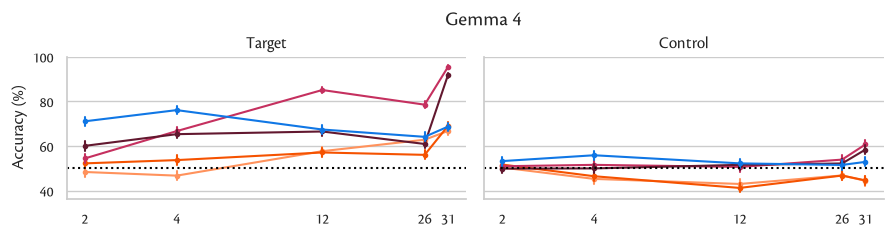

In [10]:
gemma_plot_method_comp = method_comp_plot("Gemma 4", include_legend=False)
gemma_plot_method_comp.savefig('../graphs/01a_gemma_methods_exp1.png')

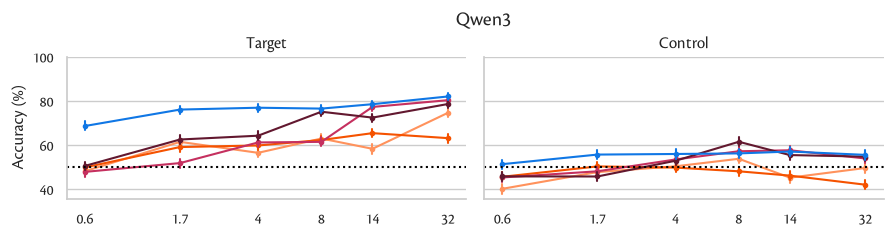

In [11]:
qwen_3_plot_method_comp = method_comp_plot("Qwen3", include_legend=False)
qwen_3_plot_method_comp.savefig('../graphs/01b_qwen3_methods_exp1.png')

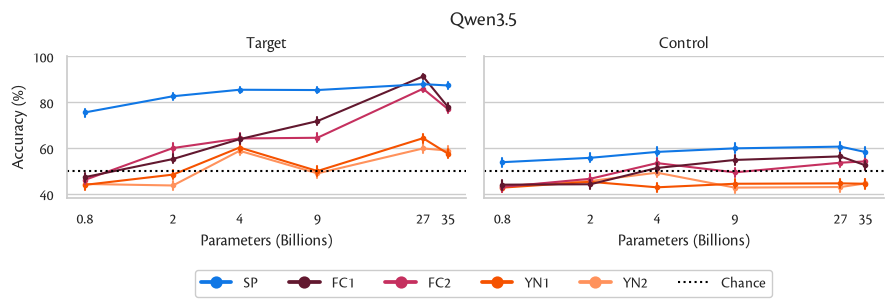

In [12]:
qwen_35_plot_method_comp = method_comp_plot("Qwen3.5")
qwen_35_plot_method_comp.savefig('../graphs/01c_qwen35_methods_exp1.png')

## Show descriptive stats

In [13]:
def make_stats(model_family, target = True):
    condition = 'Target' if target else 'Control'
    out_df = data[(data['model_family'] == model_family) & (data['condition'] == condition)]
    model_list = out_df['model'].unique()
    out_df = out_df.groupby(['model', 'data_type'])[['correct']].agg('mean')
    out_df = out_df.reset_index().pivot(index='model', columns = 'data_type', values = 'correct')
    out_df = out_df[['string_probs', 'forced_choice_1', 'forced_choice_2', 'yes_no_1', 'yes_no_2']]
    out_df = out_df.apply(lambda x: round(x * 100, 1))
    out_df = out_df.reindex(model_list)
    return(out_df)

In [14]:
make_stats('Gemma 4')

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
gemma_4_E2B,71.0,60.0,54.4,52.2,48.3
gemma_4_E4B,76.0,65.2,66.6,53.6,46.7
gemma_4_12B,67.3,66.4,85.0,57.0,57.6
gemma_4_26B_A4B,64.1,60.9,78.5,56.0,62.8
gemma_4_31B,68.6,91.7,95.3,68.9,66.7


In [15]:
make_stats('Gemma 4', target = False)

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
gemma_4_E2B,53.2,49.8,50.9,51.6,50.3
gemma_4_E4B,55.8,49.9,51.5,46.4,45.2
gemma_4_12B,52.2,51.5,50.6,41.2,43.0
gemma_4_26B_A4B,51.5,52.1,53.9,46.7,46.8
gemma_4_31B,52.8,58.3,60.6,44.5,44.4


In [16]:
make_stats('Qwen3')

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
qwen_3_0.6B,68.5,50.4,47.7,49.8,48.0
qwen_3_1.7B,76.0,62.4,51.7,59.0,61.3
qwen_3_4B,76.8,64.1,61.1,59.7,56.4
qwen_3_8B,76.4,75.0,61.3,62.2,62.9
qwen_3_14B,78.4,72.3,77.2,65.3,58.2
qwen_3_32B,81.9,78.5,80.2,63.0,74.5


In [17]:
make_stats('Qwen3', target = False)

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
qwen_3_0.6B,51.2,45.7,45.2,45.5,40.1
qwen_3_1.7B,55.6,45.7,48.0,50.2,47.7
qwen_3_4B,55.9,52.8,53.4,49.7,50.3
qwen_3_8B,56.1,61.4,57.1,48.0,53.7
qwen_3_14B,57.0,55.4,57.5,46.1,45.1
qwen_3_32B,55.5,54.7,53.8,41.9,49.5


In [18]:
make_stats('Qwen3.5')

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
qwen_3.5_0.8B,75.6,47.4,46.2,44.1,44.5
qwen_3.5_2B,82.7,55.3,60.1,48.5,43.8
qwen_3.5_4B,85.5,64.0,64.3,60.3,58.9
qwen_3.5_9B,85.4,71.9,64.6,50.1,49.1
qwen_3.5_27B,87.9,91.3,85.9,64.4,59.9
qwen_3.5_35B_A3B,87.4,78.0,77.1,57.7,59.0


In [19]:
make_stats('Qwen3.5', target=False)

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
qwen_3.5_0.8B,53.9,44.1,43.2,42.9,43.5
qwen_3.5_2B,55.9,44.3,46.7,45.4,45.7
qwen_3.5_4B,58.4,51.4,53.5,43.0,49.4
qwen_3.5_9B,60.0,54.9,49.5,44.5,42.9
qwen_3.5_27B,60.7,56.5,53.7,44.7,43.1
qwen_3.5_35B_A3B,58.4,52.6,54.3,44.5,44.7


## Show top performers

In [20]:
top_performers = pd.concat([make_stats('Gemma 4'), make_stats('Qwen3'), make_stats('Qwen3.5')])
top_performers = (
    top_performers.reset_index()
      .melt(
          id_vars=["model"],
          var_name="data_type",
          value_name="accuracy"
      )
      .sort_values("accuracy", ascending=False)
      .reset_index(drop=True)
)
top_performers.head(10)

,model,data_type,accuracy
0,gemma_4_31B,forced_choice_2,95.3
1,gemma_4_31B,forced_choice_1,91.7
2,qwen_3.5_27B,forced_choice_1,91.3
3,qwen_3.5_27B,string_probs,87.9
4,qwen_3.5_35B_A3B,string_probs,87.4
5,qwen_3.5_27B,forced_choice_2,85.9
6,qwen_3.5_4B,string_probs,85.5
7,qwen_3.5_9B,string_probs,85.4
8,gemma_4_12B,forced_choice_2,85.0
9,qwen_3.5_2B,string_probs,82.7


## Best models by category

In [22]:
data_best_models = data.copy()
data_best_models = data_best_models[data_best_models['model_nat'].isin(['Gemma 4 31B', 'Qwen3 32B', 'Qwen3.5 27B'])]
data_best_models = data_best_models[data_best_models['condition'] == 'Target']
data_best_models = data_best_models[data_best_models['Method'].isin(['SP', 'FC1', 'FC2'])]

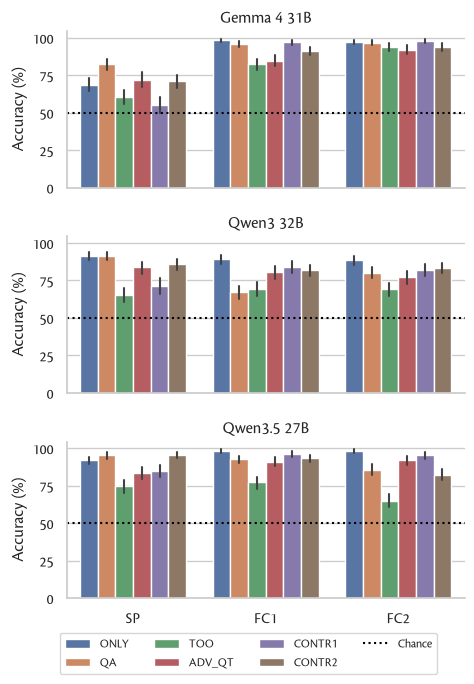

In [27]:
g = sns.catplot(
        data=data_best_models,
        hue='category',
        # hue_order=['YN2', 'YN1', 'FC2', 'FC1', 'SP'],
        y='correct',
        x='Method',
        kind='bar',
        col='model_nat',
        # col_order = ['Target', 'Control'] if include_controls else ['Target'],
        # native_scale=True,
        # palette=CATEGORY_PALETTE,
        estimator=lambda x: (sum(x) / len(x)) * 100,
        col_wrap=1,
        height=2.25,
        aspect=2.2
    )

g.set_titles('{col_name}')

for ax in g.axes.flat:
    ax.set_xlabel('')
    ax.set_ylabel('Accuracy (%)')
    ax.axhline(
        50,
        linestyle=':',
        color='black',
        linewidth=1.5,
    )
    for line in ax.lines:
        line.set_linewidth(1.5)
        line.set_markersize(2)

legend = g.legend
    
# Get its handles and labels
handles = legend.legend_handles
labels = [text.get_text() for text in legend.texts]

# Add chance line
handles.append(
    Line2D(
        [0], [0],
        color='black',
        linestyle=':',
        linewidth=1.5
    )
)
labels.append('Chance')

# Remove old legend
legend.remove()

# Recreate it
g.figure.legend(
    handles=handles,
    labels=labels,
    title='',
    bbox_to_anchor = (0.45, -.02),
    loc='lower center',
    ncols = 4,
    fontsize=9
    # framealpha = legendalpha
)

g.savefig('../graphs/02_cats_exp1.png')